# PEPSI: masking or modelling the stellar lines

Stellar absorption lines sit among the telluric lines. If the fit takes them for
telluric absorption, the fitted molecular columns are biased. gtellcorr offers two ways
to prevent this: the **mask route** leaves the stellar lines out of the fit, and the
**template route** models them with a stellar template. This notebook explains the idea
behind each route and applies both to the same PEPSI exposure of the K dwarf TOI-2076.

We proceed in four steps:

1. **The exposure.** We read one exposure of the night of the first notebook.
2. **The atmospheric profile.** As before, it comes from ERA5.
3. **Two routes.** We write down the model of each route, prepare the inputs they
   share, and run both fits.
4. **The two fits compared.** We look at the fits and the fitted parameters, and
   discuss which route to choose.

**What you need.** Everything of the night notebook (`01_pepsi_toi2076_night`), which
must have been run first: this notebook takes its stellar template and its radial
velocities. iSpec (the `ispec_dir` setting) measures the stellar lines of the mask. The
exposure used here, `pepsir.20250619.072`, is not public yet; the notebook is published
with its results, so the steps can be followed without it.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import gtellcorr as gtc
from gtellcorr.config import dumps_config
from gtellcorr.constants import C_KMS
from gtellcorr.data.atmosphere import full_profile_for_exposure
from gtellcorr.plotting import plot_order_fit, plot_profiles

data = Path(os.environ.get("GTELLCORR_PAPER_DATA", "paper_data"))
runs = Path(os.environ.get("GTELLCORR_PAPER_OUT", "paper_runs"))
output = runs / "pepsi_toi2076_routes"
settings = gtc.Settings.load()
plt.rcParams["figure.dpi"] = 72  # keeps the figures in the notebook small
print("gtellcorr", gtc.__version__)

gtellcorr 0.10.0


## 1. The exposure

We use `pepsir.20250619.072`, taken near the zenith about an hour into the night. We
read the night as in the first notebook and select the exposure with
`Observation.select`; the whole night is needed again in Section 3, where the
stellar-line mask is measured on all 60 exposures.

To see where the stellar and the telluric lines meet, let's plot a stretch of water lines
together with the template of the first notebook, shifted to the radial velocity
measured there. The lines of the template are stellar; the others are telluric.

pepsir.20250619.072.dxt.nor: 04:17 UTC, airmass 1.01, median S/N 288


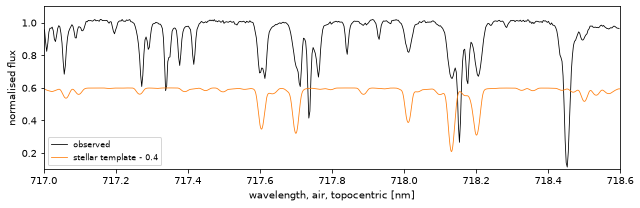

In [2]:
star = gtc.Star(name="TOI-2076", teff=5180.0, logg=4.608, feh=0.0, vsini_kms=5.0, vsys_kms=-12.5)
night = gtc.Observation.from_directory(data / "pepsi_toi2076", instrument="LBT/PEPSI", target=star)
token = "pepsir.20250619.072"
obs = night.select(include=[token])
exposure = obs.exposures[0]
order = obs.read_order(exposure, 0)
print(
    f"{exposure.name}: {exposure.time_utc:%H:%M} UTC, airmass {exposure.airmass:.2f}, "
    f"median S/N {np.median(order.flux / order.err):.0f}"
)

night_run = runs / "pepsi_toi2076_night"
(template,) = night_run.glob("*/*/*/template_stellar_spectrum/data/*_rest.dat")
(night_rvs,) = night_run.glob("*/*/*/Radial_Velocities/data/*_rv.csv")
rv_kms = pd.read_csv(night_rvs).set_index("file").loc[exposure.name, "rv_kms"]
wave_rest, flux_template = np.loadtxt(template, unpack=True)

lo, hi = 717.0, 718.6
sel = (order.wave_fit > lo) & (order.wave_fit < hi)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(order.wave_fit[sel], order.flux[sel], lw=0.8, color="k", label="observed")
ax.plot(
    wave_rest * (1 + rv_kms / C_KMS),
    flux_template - 0.4,
    lw=0.8,
    color="C1",
    label="stellar template - 0.4",
)
ax.set_xlim(lo, hi)
ax.set_ylim(0.1, 1.1)
ax.set_xlabel("wavelength, air, topocentric [nm]")
ax.set_ylabel("normalised flux")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()

Many lines of the observed spectrum have a stellar counterpart, and several stellar
lines fall on top of water lines. These blends are what the two routes treat
differently.

## 2. The atmospheric profile

As in the first notebook, the profile of the exposure combines ERA5 below and
NRLMSIS-00 above:

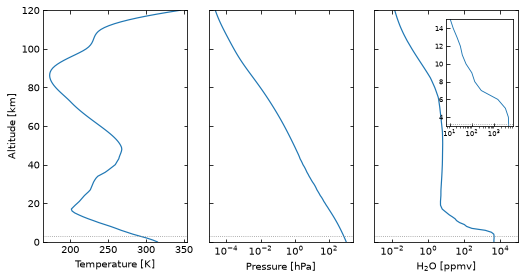

In [3]:
profile = full_profile_for_exposure(exposure, obs.instrument, settings=settings)
fig, axes = plot_profiles(
    {f"{exposure.time_utc:%H:%M} UTC": profile},
    site_alt_km=exposure.site.alt_m / 1000,
    inset_z_km=(3.0, 15.0),
)

## 3. Two routes

### The model of each route

Both routes fit the model of the first notebook,

$$F_{\rm model}(\lambda) = C(\lambda)\, M(\lambda)\, \left[K_R \ast T\right](\lambda),$$

and minimise

$$\chi^2 = \sum_{i\,\in\,\rm fit} \left(\frac{F_i - F_{{\rm model},i}}{\sigma_i}\right)^2$$

over the pixels $i$ kept for the fit. They differ in two things: what $M$ is, and which
pixels are kept.

- **Mask route** (`stellar = "mask"`): $M = 1$. The star is not modelled. Instead, the
  pixels of its lines are left out of $\chi^2$, together with the cores of the strong
  telluric lines and the activity lines.
- **Template route** (`stellar = "template"`): $M$ is a stellar template, shifted to
  the radial velocity (RV) of the star in the exposure. The stellar lines are now part
  of the model, so their pixels stay in $\chi^2$; only the strong telluric cores and the
  activity lines are left out.

The two routes pay in different ways. The mask route needs no model of the star, so its
result does not depend on how well a synthetic spectrum matches the star. The price is
the masked pixels, among them every telluric line blended with a stellar line, and the
lines the mask misses, which stay in $\chi^2$ as if they were telluric. The template
route keeps every pixel, but any mismatch between the template and the star enters the
fit.

### Looking at the settings

Every setting of a fit lives in a `gtc.FitConfig`. `gtc.FitConfig()` holds the
defaults, and `gtellcorr.config.dumps_config` writes a configuration as TOML, the format
of the `[fit]` part of a run file, with one table per group of settings. By default
every setting comes with its description (`comments=True`); here we leave the
descriptions out to keep the listing shorter. Let's print the default configuration:

In [4]:
default = gtc.FitConfig()
print(dumps_config(default, comments=False))

# gtellcorr configuration. Parameters left out keep their default values.
schema_version = 5

[fit]
stellar = "mask"
relcol_mode = "joint_orders"
on_missing_stellar_data = "generate"

[fit.continuum]
order = 5
sigma_clip = [2.0, 3.0]
niter = 1
output_niter = 5

[fit.lsf]
kind = "gauss"
fit_shape = false
fit_resolution = true

[fit.lsf.shape]
sgauss = 2.0
voigt = 0.2

[fit.lsf.shape_bounds]
sgauss = [1.2, 4.0]
voigt = [0.0, 0.9]

[fit.wavelength]
fit = false
order = 0
scope = "order"
bounds_kms = [-1.0, 1.0]

[fit.molecules.h2o]
fit = true
relcol = 1.0
bounds = [0.01, 100.0]
bands_nm = [
    [570.0, 605.0],
    [640.0, 690.0],
    [700.0, 745.0],
    [780.0, 840.0],
    [890.0, 985.0],
    [1080.0, 1200.0],
    [1300.0, 1500.0],
    [1750.0, 2050.0],
    [2500.0, 3000.0],
    [5500.0, 7500.0],
]

[fit.molecules.co2]
fit = false
relcol = 1.0
bounds = [0.5, 2.0]
bands_nm = [
    [1570.0, 1630.0],
    [1950.0, 2100.0],
    [2700.0, 2900.0],
    [4200.0, 4450.0],
    [4750.0, 5200.0],
    [

Settings that are empty by default, such as `stellar_model.template_file`, do not
appear: TOML has no empty value.

A configuration can be changed in three ways, which give the same result:

- `gtc.FitConfig.from_dict(...)` builds one from a nested dictionary with the tables of
  the TOML; every setting you leave out keeps its default. We use this below.
- `replace` returns a copy of a configuration, or of one of its groups, with some
  settings changed, for example `default.replace(stellar="template")`.
- `config.save("fit.toml")` writes the TOML to a file, which you can edit and read back
  with `gtc.FitConfig.load("fit.toml")`.

Every configuration is checked when it is built: an unknown name or a value out of
range raises an error that names the setting.

### The mask route

The mask is a list of wavelength windows in the rest frame of the star. By default
gtellcorr measures it on the master spectrum of the run, its exposures shifted to the
stellar rest frame and co-added. In this master, iSpec finds the
absorption lines and keeps those that match an atomic transition of the selected
elements and are deep enough. Telluric lines are not kept, since they have no atomic
counterpart.

With a single exposure, the master would be that exposure: noisy, and with the telluric
lines of one airmass. We therefore work in two steps. First we measure the mask on the
master spectrum of the whole night, running only the preparation step of the pipeline
(`Pipeline.prepare`, no fit). Then we fit our exposure with the windows of the night.
These are the settings of the mask route; we write them all out, although most are the
defaults:

- `stellar = "mask"`: the stellar lines are masked, $M = 1$;
- `stellar_model.template_file`: the template, which the mask route needs for the RVs
  that place the windows on each exposure;
- `masks.stellar_linemask.from_spectrum = "master"`: the lines are measured on the
  master spectrum (`"template"` would mask every line of the template instead);
- `stellar_model.line_elements` and `stellar_model.line_min_depth`: the elements whose
  lines are kept (here the default nine), and the depth a line must reach (0.10);
- `masks.stellar_linemask.blend = "off"`: every measured line is masked, also where it
  blends with a telluric line;
- `masks.stellar_linemask.user_file`: in the second step, the windows measured on the
  night. They replace the measurement, and gtellcorr shifts them by the RV of the
  exposure;
- `wavelength.fit = true`: the wavelength correction is fitted, as in the first
  notebook.

In [5]:
measure_config = gtc.FitConfig.from_dict(
    {
        "stellar": "mask",
        "stellar_model": {
            "template_file": str(template),
            "line_elements": ["Fe", "Ca", "Na", "Mg", "Ti", "Cr", "Ni", "Si", "Mn"],
            "line_min_depth": 0.10,
        },
        "masks": {"stellar_linemask": {"from_spectrum": "master", "blend": "off"}},
    }
)
prepare = gtc.Pipeline(
    night,
    measure_config,
    output_dir=runs / "pepsi_toi2076_night_mask",
    settings=settings,
    plot=False,
)
prepare.prepare()
(windows_file,) = (prepare.layout.root / "mask_spectral_line" / "data").glob(
    "*_stellarlinemask_rest.txt"
)
windows = np.loadtxt(windows_file, ndmin=2)
print(f"stellar-line mask: {len(windows)} windows, {np.sum(windows[:, 1] - windows[:, 0]):.2f} nm")

mask_config = gtc.FitConfig.from_dict(
    {
        "stellar": "mask",
        "stellar_model": {"template_file": str(template)},
        "masks": {"stellar_linemask": {"user_file": str(windows_file)}},
        "wavelength": {"fit": True},
    }
)
results = {
    "mask": gtc.run(obs, mask_config, output_dir=output / "072_mask", settings=settings, plot=False)
}

stellar-line mask: 249 windows, 25.00 nm


### The template route

For the template route, the template is all we need, and we pass the same file. A
template can come from three places: synthesised with pySME from the stellar parameters
and a VALD line list (`stellar_model.backend = "pysme"`, the default), synthesised with
iSpec (`backend = "ispec"`), or your own file (`stellar_model.template_file`), such as a
PHOENIX spectrum or a telluric-free observation. The user manual describes each of them,
and what a template file must contain.

These are the settings of the template route, again written out in full:

- `stellar = "template"`: the star is modelled, $M$ is the template;
- `stellar_model.template_file`: the template synthesised by the first notebook. With a
  file, gtellcorr synthesises nothing;
- `stellar_model.template_medium = "air"` and `stellar_model.template_frame = "rest"`:
  the file has air wavelengths in the rest frame of the star, so it is shifted to the
  RV of the exposure. Templates synthesised by gtellcorr are written this way;
- `stellar_model.template_resolution`, left unset: the template is already at the
  resolving power of the spectra, so it is not broadened;
- `stellar_model.fit_shift = false`: the template stays at the measured RV, with no
  velocity of its own fitted;
- `wavelength.fit = true`: as for the mask route.

In [6]:
template_config = gtc.FitConfig.from_dict(
    {
        "stellar": "template",
        "stellar_model": {
            "template_file": str(template),
            "template_medium": "air",
            "template_frame": "rest",
            "fit_shift": False,
        },
        "wavelength": {"fit": True},
    }
)
results["template"] = gtc.run(
    obs,
    template_config,
    output_dir=output / "072_template",
    settings=settings,
    plot=False,
)

## 4. The two fits compared

`plot_order_fit` draws the two fits, the mask route first. In each upper panel are the
observed spectrum (black), the telluric model $C T$ (green) and the continuum $C$ (blue,
dashed); the template route adds the stellar model $C M$ (orange). Grey bands mark the
pixels left out of $\chi^2$. The lower panels show the corrected spectra,
$F / (C T)$.

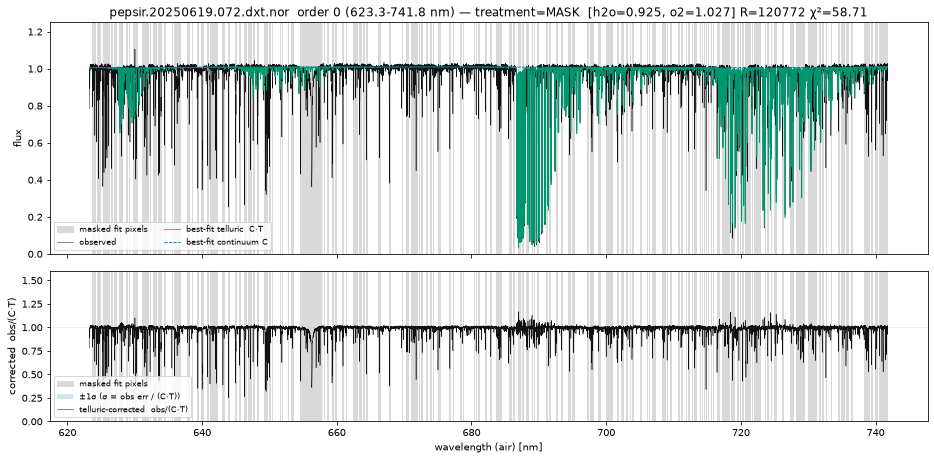

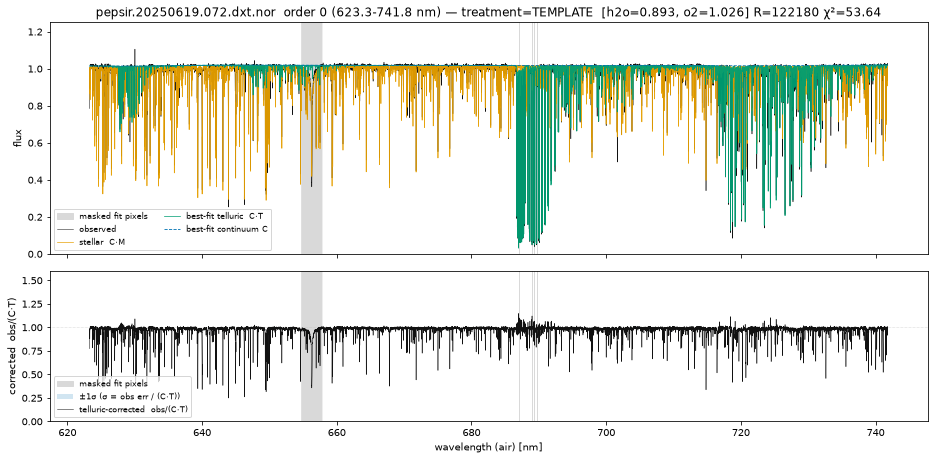

In [7]:
for res in results.values():
    fig, axes = plot_order_fit(str(res.exposures[0].path), order=0, out=False)

The grey bands show the main difference between the routes. With the mask, a quarter
of the order is left out, scattered over hundreds of stellar lines; with the template,
only a few percent, the saturated cores of the O{sub}`2` B band and H-alpha. Both
corrections remove the water and O{sub}`2` lines, and in both the largest residuals sit
in the saturated line cores, where dividing by a transmission close to zero amplifies
the noise and any error of the model.

Let's compare the fitted parameters:

In [8]:
rows = []
for route, res in results.items():
    row = res.exposures[0].order_table.iloc[0]
    relcol = json.loads(row["relcol"])
    rows.append(
        {
            "route": route,
            "H2O": relcol["h2o"],
            "O2": relcol["o2"],
            "R": row["resolution"],
            "reduced chi2": row["chi2_reduced"],
            "left out [%]": 100 * row["masked_frac"],
        }
    )
table = pd.DataFrame(rows).set_index("route")
table.round(4)

,H2O,O2,R,reduced chi2,left out [%]
route,,,,,
mask,0.9246,1.0272,120772.2212,58.7134,23.0042
template,0.8927,1.0264,122179.5352,53.6446,2.4899


The O{sub}`2` columns agree to 0.1 % and the resolving powers to about 1 %, and the
reduced $\chi^2$ is lower for the template route although it keeps the stellar lines in
the fit. The water columns differ: the mask route finds 3.6 % more water than the
template route.

One real exposure cannot tell which is closer to the truth, but an injection-recovery
simulation of PEPSI spectra, where the truth is known, shows the direction. For a K
dwarf at a resolving power of 50 000 or more, the mask route recovered water 1.1 % too
high on median (16-84 % range +0.2 to +3.0 %), the template route within 0.1 % (-0.3 to
+0.9 %). The bias of the mask route comes from the stellar absorption that stays in
$\chi^2$: the mask finds the clear atomic lines, but in the simulation 35-46 % of the
stellar absorption that falls on telluric lines of G and K stars stayed unmasked, and
the fit attributed it to water. The difference found here has the same sign and is
somewhat larger.

### Which route to choose

- **With a template that matches the star, use the template route.** For the A, G and
  K stars of the simulation it recovered water within 0.1 % on median, against -0.7 to
  +1.1 % for the mask route, and it does not depend on finding every stellar line.
- **Without a reliable template, use the mask route**: when the stellar parameters are
  unknown or uncertain, or for a peculiar star. For a target that is not a star, give
  the windows of its lines yourself (`masks.stellar_linemask.user_file`).
- **Hot, fast-rotating stars**: their lines are broad and shallow, and the atomic line
  search misses most of them. Use the template route, or build the mask from the
  template (`masks.stellar_linemask.from_spectrum = "template"`).
- **M dwarfs**: neither the atomic line search nor a synthetic template describes their
  molecular bands well. In the simulation, where the true spectrum was a PHOENIX model
  and the template a pySME synthesis, O{sub}`2` came out 40-47 % too high with both
  routes. For these stars the result is only as good as the template, so use the best
  one available, such as an observed telluric-free spectrum of a similar star.